# CS16 — Phase 4: 3D U-Net Baseline Preflight

## Training intentionally not executed

This notebook freezes and validates the complete baseline contract before the first research run:
exact train/validation boundaries, paired transforms, the 11-class MONAI 3D U-Net, loss/optimizer/
scheduler specifications, full-volume validation policy, provenance, and artifact safeguards.

> **Hard boundary:** this notebook performs one evaluation-mode, gradient-free shape check with randomly
> initialized weights. It creates no optimizer, calls no backward pass, completes no epoch, writes no
> checkpoint, and reports no segmentation-quality result. The locked test split is never resolved or read.


## Research protocol frozen by this preflight

| Component | Locked baseline rule |
|---|---|
| Development data | Official `train=1082`, `val=57`; patient-level split |
| Test data | 89 cases locked before path resolution |
| Input | Calibrated CT, RAS, 1.5 mm, fixed `[-1000,1000] HU → [0,1]` |
| Training ROI | Deterministic class-balanced `96³` patches |
| Validation | Complete volumes with future sliding-window inference; never random patches |
| Spatial augmentation | Paired small affine; bilinear CT and nearest-neighbour label |
| Laterality | Naïve flips forbidden because IDs 3/4 and 9/10 are left/right pairs |
| Network | MONAI 3D U-Net, 1 input channel, 11 output channels |
| Objective | Dice + Cross-Entropy; background excluded from Dice term |
| Optimization | AdamW, AMP, gradient accumulation; configured but not invoked here |
| Metrics | Per-organ Dice and HD95 with valid-case counts and explicit empty-target handling |


In [1]:
from __future__ import annotations

import json
import os
import platform
import sys
from dataclasses import asdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import monai
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from matplotlib.colors import ListedColormap
from monai.metrics import compute_hausdorff_distance
from monai.transforms import Randomizable
from torch.utils.data import DataLoader

PROJECT_ROOT = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "configs" / "baseline_unet_v1.yaml").is_file()
).resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset import (
    development_cases,
    get_development_case,
    load_organ_schema,
    load_preprocessing_spec,
    load_validated_manifest,
    normalize_ct,
    sample_class_balanced_patch,
)
from src.training import (
    ExactSplitPatchDataset,
    ExactSplitVolumeDataset,
    TrainingCounters,
    TrainingDisabledError,
    assert_training_authorized,
    atomic_write_json,
    build_loss,
    build_model,
    build_train_transform,
    hash_artifacts,
    load_baseline_config,
    model_state_sha256,
    prepare_case,
    training_artifact_inventory,
    validate_baseline_contract,
)

RUN_TRAINING = False
assert RUN_TRAINING is False, "This notebook is a preflight, not a training run"

DATASET_ROOT = Path(
    os.environ.get("TOTALSEG_DATASET_ROOT", PROJECT_ROOT / "Totalsegmentator_dataset_v201")
).resolve()
BASELINE_CONFIG_PATH = PROJECT_ROOT / "configs" / "baseline_unet_v1.yaml"
ORGAN_CONFIG_PATH = PROJECT_ROOT / "configs" / "organs_v1.yaml"
DATASET_CONFIG_PATH = PROJECT_ROOT / "configs" / "dataset.yaml"
MANIFEST_PATH = PROJECT_ROOT / "data" / "splits" / "dataset_manifest.json"
GPU_REPORT_PATH = PROJECT_ROOT / "outputs" / "environment" / "gpu_verification.json"
PHASE3_REPORT_PATH = PROJECT_ROOT / "outputs" / "phase3" / "qa_summary.json"

torch.manual_seed(42)
np.random.seed(42)
torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

artifact_inventory_before = training_artifact_inventory(PROJECT_ROOT)
print(f"Project root       : {PROJECT_ROOT}")
print(f"Python             : {platform.python_version()}")
print(f"PyTorch / MONAI    : {torch.__version__} / {monai.__version__}")
print(f"RUN_TRAINING       : {RUN_TRAINING}")
print(f"Prior Phase-4 training artifacts: {len(artifact_inventory_before)}")


Project root       : F:\csstdy
Python             : 3.13.12
PyTorch / MONAI    : 2.13.0+cu130 / 1.6.0
RUN_TRAINING       : False
Prior Phase-4 training artifacts: 0


## 1. Load immutable contracts and prove the test lock

Absolute dataset paths are runtime inputs and are excluded from experiment fingerprints. Every reusable
loader accepts only manifest records from the exact declared split. The synthetic test request below must
fail before its deliberately invalid dataset root can be resolved.


In [2]:
schema = load_organ_schema(ORGAN_CONFIG_PATH)
manifest = load_validated_manifest(MANIFEST_PATH, schema)
preprocessing = load_preprocessing_spec(DATASET_CONFIG_PATH)
baseline = load_baseline_config(BASELINE_CONFIG_PATH)
gpu_report = json.loads(GPU_REPORT_PATH.read_text(encoding="utf-8"))
phase3_report = json.loads(PHASE3_REPORT_PATH.read_text(encoding="utf-8"))
contract = validate_baseline_contract(
    baseline,
    manifest=manifest,
    schema=schema,
    preprocessing=preprocessing,
    gpu_report=gpu_report,
)

try:
    ExactSplitVolumeDataset(
        project_root=PROJECT_ROOT,
        dataset_root=Path("Z:/POISON_PATH_MUST_NOT_RESOLVE"),
        manifest=manifest,
        schema=schema,
        preprocessing=preprocessing,
        preprocessing_sha256=contract["preprocessing_sha256"],
        config=baseline,
        split="test",
        allow_cache_write=False,
    )
except PermissionError:
    test_lock_enforced_pre_io = True
else:
    raise AssertionError("Locked test split unexpectedly reached dataset construction")

train_records = development_cases(manifest, baseline.train_split)
validation_records = development_cases(manifest, baseline.validation_split)
assert len(train_records) == 1082 and len(validation_records) == 57
assert not ({case["case_id"] for case in train_records} & {case["case_id"] for case in validation_records})
assert test_lock_enforced_pre_io

fingerprint_table = pd.DataFrame(
    [
        ("Manifest", baseline.manifest_sha256),
        ("10-organ schema", baseline.organ_schema_sha256),
        ("Preprocessing", baseline.preprocessing_sha256),
        ("Baseline YAML", baseline.config_sha256),
        ("Experiment", baseline.experiment_fingerprint()),
        ("GPU validation run", gpu_report["run_id"]),
    ],
    columns=["Contract", "SHA-256 / run ID"],
)
split_table = pd.DataFrame(
    [{"Split": key, "Cases": value, "Permitted in this notebook": key in {"train", "val"}}
     for key, value in contract["split_counts"].items()]
)
display(fingerprint_table.style.hide(axis="index"))
display(split_table.style.hide(axis="index"))


Contract,SHA-256 / run ID
Manifest,4c94df936370ee913b0202fc5a34cba9843727d8dabb0552a3b8160dea223d8d
10-organ schema,082fa87535d1a4c91d0eaf4aa074ebf297cd0ec386183643038bf2c583989c05
Preprocessing,92ec417172ae9a564135fed9bb0ae173de5305651f96220c57b29655e92b8c71
Baseline YAML,2778c24eadf61c3172cf23e67b55fdba2e7739b85eddc6a25cf7cfbd5a3e3bfc
Experiment,a0de203536b032ca4f033f04b887a546f08c1b14eeb7bbbf1449b52b863af8fb
GPU validation run,gpu-20260818T094306Z-173ab4b6


Split,Cases,Permitted in this notebook
train,1082,True
val,57,True
test,89,False


## 2. Construct exact-split dataset interfaces

The training interface returns class-balanced patches. The validation interface returns complete volumes
for future sliding-window inference. Creating these interfaces performs no NIfTI read; only the single
frozen training case used later for QA is loaded.


In [3]:
train_dataset = ExactSplitPatchDataset(
    project_root=PROJECT_ROOT,
    dataset_root=DATASET_ROOT,
    manifest=manifest,
    schema=schema,
    preprocessing=preprocessing,
    preprocessing_sha256=contract["preprocessing_sha256"],
    config=baseline,
    split="train",
    augment=True,
    allow_cache_write=baseline.notebook_cache_write_enabled,
)
validation_dataset = ExactSplitVolumeDataset(
    project_root=PROJECT_ROOT,
    dataset_root=DATASET_ROOT,
    manifest=manifest,
    schema=schema,
    preprocessing=preprocessing,
    preprocessing_sha256=contract["preprocessing_sha256"],
    config=baseline,
    split="val",
    allow_cache_write=baseline.notebook_cache_write_enabled,
)

validation_randomizables = [
    type(transform).__name__
    for transform in validation_dataset.transform.transforms
    if isinstance(transform, Randomizable)
]
assert len(train_dataset) == 1082
assert len(validation_dataset) == 57
assert validation_randomizables == []
assert train_dataset.allow_cache_write is False and validation_dataset.allow_cache_write is False

dataset_contract_table = pd.DataFrame(
    [
        {"Interface": "Training", "Cases/items": len(train_dataset), "Output": "96³ class-balanced patch", "Random": "train only"},
        {"Interface": "Validation", "Cases/items": len(validation_dataset), "Output": "complete volume", "Random": "none"},
        {"Interface": "Test", "Cases/items": 89, "Output": "locked", "Random": "not applicable"},
    ]
)
display(dataset_contract_table.style.hide(axis="index"))


Interface,Cases/items,Output,Random
Training,1082,96³ class-balanced patch,train only
Validation,57,complete volume,none
Test,89,locked,not applicable


## 3. Rebuild the frozen Phase 3 patch

`s0014`, sample index 14 is reconstructed through the same loader, merge priority, geometry, HU window,
normalization, and sampler used in Phase 3. Cache writes are disabled for this notebook.


In [4]:
primary_case_id = phase3_report["primary_case"]
primary_case = get_development_case(manifest, primary_case_id)
assert primary_case["split"] == "train"

prepared = prepare_case(
    project_root=PROJECT_ROOT,
    dataset_root=DATASET_ROOT,
    case=primary_case,
    schema=schema,
    preprocessing=preprocessing,
    preprocessing_sha256=contract["preprocessing_sha256"],
    config=baseline,
    allow_cache_write=False,
)
normalized = normalize_ct(prepared.ct_hu, preprocessing)
image_patch, label_patch_3d, patch_trace = sample_class_balanced_patch(
    normalized,
    prepared.label,
    prepared.ct_hu,
    preprocessing,
    case_id=primary_case_id,
    sample_index=phase3_report["foreground_patch_trace"]["sample_index"],
)
exclusive_counts = {
    label.name: int(np.count_nonzero(prepared.label == label.id)) for label in schema.labels
}
normalized_patch_trace = json.loads(json.dumps(asdict(patch_trace)))
assert normalized_patch_trace == phase3_report["foreground_patch_trace"]
assert exclusive_counts == phase3_report["primary_exclusive_counts"]
assert image_patch.shape == (1, 96, 96, 96) and image_patch.dtype == np.float32
assert label_patch_3d.shape == (96, 96, 96) and label_patch_3d.dtype == np.uint8

access_ledger = [{"case_id": primary_case_id, "split": "train", "purpose": "preflight_patch_qa"}]
raw_item = {
    "image": torch.from_numpy(np.ascontiguousarray(image_patch)),
    "label": torch.from_numpy(np.ascontiguousarray(label_patch_3d[None].astype(np.int64))),
}
preflight_loader = DataLoader([raw_item], batch_size=1, shuffle=False, num_workers=0)
preflight_batch = next(iter(preflight_loader))
assert preflight_batch["image"].shape == (1, 1, 96, 96, 96)
assert preflight_batch["label"].shape == (1, 1, 96, 96, 96)
assert preflight_batch["image"].dtype == torch.float32
assert preflight_batch["label"].dtype == torch.int64

del normalized, prepared
patch_table = pd.DataFrame(
    [
        ("Case / split", f"{primary_case_id} / train"),
        ("Sampler mode", patch_trace.mode),
        ("Selected class", f"{patch_trace.selected_class_id} (pancreas)"),
        ("Image batch", str(tuple(preflight_batch["image"].shape))),
        ("Label batch", str(tuple(preflight_batch["label"].shape))),
        ("Image range", f"[{image_patch.min():.3f}, {image_patch.max():.3f}]"),
        ("Cache write", "disabled"),
    ],
    columns=["Check", "Verified value"],
)
display(patch_table.style.hide(axis="index"))


Check,Verified value
Case / split,s0014 / train
Sampler mode,foreground_class_balanced
Selected class,6 (pancreas)
Image batch,"(1, 1, 96, 96, 96)"
Label batch,"(1, 1, 96, 96, 96)"
Image range,"[0.161, 1.000]"
Cache write,disabled


## 4. Paired augmentation QA

One deterministic copy of the real patch is augmented for visualization only. Geometry is shared by image
and label; intensity transforms affect only the image; labels are re-cast to integer after nearest-neighbour
resampling. No flips are present because laterality-aware ID swapping is not part of baseline v1.


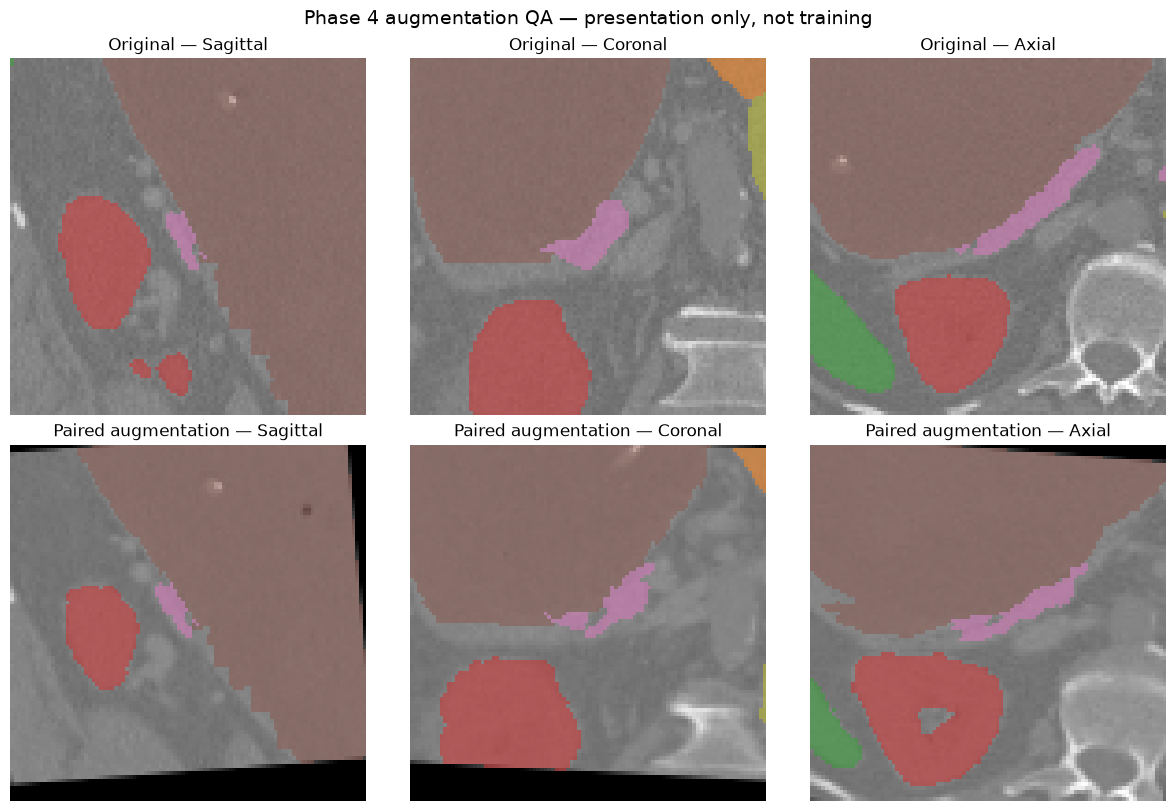

Saved: outputs\phase4\augmentation_qa.png


In [5]:
train_transform = build_train_transform(baseline)
assert all("Flip" not in type(transform).__name__ for transform in train_transform.transforms)
train_transform.set_random_state(seed=4242)
augmented_a = train_transform({key: value.clone() for key, value in raw_item.items()})
train_transform.set_random_state(seed=4242)
augmented_b = train_transform({key: value.clone() for key, value in raw_item.items()})

assert torch.equal(augmented_a["image"], augmented_b["image"])
assert torch.equal(augmented_a["label"], augmented_b["label"])
assert augmented_a["image"].shape == raw_item["image"].shape
assert augmented_a["label"].shape == raw_item["label"].shape
assert augmented_a["image"].dtype == torch.float32
assert augmented_a["label"].dtype == torch.int64
assert torch.isfinite(augmented_a["image"]).all()
assert 0.0 <= float(augmented_a["image"].min()) <= float(augmented_a["image"].max()) <= 1.0
source_ids = set(int(value) for value in torch.unique(raw_item["label"]).tolist())
augmented_ids = set(int(value) for value in torch.unique(augmented_a["label"]).tolist())
assert augmented_ids <= source_ids <= set(range(11))
augmentation_mean_absolute_change = float(
    torch.mean(torch.abs(augmented_a["image"] - raw_item["image"])).item()
)
assert augmentation_mean_absolute_change > 0

label_colors = plt.cm.tab20(np.linspace(0, 1, 11))
label_colors[0, 3] = 0
label_cmap = ListedColormap(label_colors)

def show_plane(ax, image, label, axis, index, title):
    image_slice = np.take(image, index, axis=axis).T
    label_slice = np.take(label, index, axis=axis).T
    ax.imshow(image_slice, cmap="gray", origin="lower", vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(label_slice == 0, label_slice), cmap=label_cmap, origin="lower", vmin=0, vmax=10, alpha=0.50)
    ax.set_title(title)
    ax.axis("off")

original_image = raw_item["image"][0].numpy()
original_label = raw_item["label"][0].numpy()
augmented_image = augmented_a["image"][0].cpu().numpy()
augmented_label = augmented_a["label"][0].cpu().numpy()
centers = tuple(size // 2 for size in baseline.roi_size)
planes = ((0, centers[0], "Sagittal"), (1, centers[1], "Coronal"), (2, centers[2], "Axial"))
figure, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
for column, (axis, index, name) in enumerate(planes):
    show_plane(axes[0, column], original_image, original_label, axis, index, f"Original — {name}")
    show_plane(axes[1, column], augmented_image, augmented_label, axis, index, f"Paired augmentation — {name}")
figure.suptitle("Phase 4 augmentation QA — presentation only, not training", fontsize=14)
augmentation_path = PROJECT_ROOT / baseline.augmentation_figure
augmentation_path.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(augmentation_path, dpi=160, bbox_inches="tight")
plt.show()
print(f"Saved: {augmentation_path.relative_to(PROJECT_ROOT)}")


## 5. Baseline model and objective contract

This is the research baseline, not the small network used by the earlier GPU smoke test. The optimizer and
scheduler remain specifications only; they are deliberately not instantiated in this notebook.


In [6]:
torch.manual_seed(baseline.random_seed)
model = build_model(baseline)
criterion = build_loss(baseline)  # constructed, never evaluated against random predictions
parameter_count = sum(parameter.numel() for parameter in model.parameters())
trainable_parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
model_hash_before = model_state_sha256(model)
assert parameter_count == 4_817_434
assert parameter_count == trainable_parameter_count
assert all(parameter.grad is None for parameter in model.parameters())

model_table = pd.DataFrame(
    [
        ("Implementation", baseline.model_implementation),
        ("Input → output channels", f"{baseline.in_channels} → {baseline.out_channels}"),
        ("Channels", str(baseline.channels)),
        ("Strides", str(baseline.strides)),
        ("Residual units", baseline.num_res_units),
        ("Parameters", f"{parameter_count:,}"),
        ("Loss", "DiceCELoss (foreground Dice + Cross-Entropy)"),
        ("Planned optimizer", f"AdamW, lr={baseline.learning_rate:g}, weight_decay={baseline.weight_decay:g}"),
        ("Optimizer instantiated", False),
        ("Training enabled", baseline.training_enabled),
    ],
    columns=["Field", "Locked value"],
)
display(model_table.style.hide(axis="index"))


Field,Locked value
Implementation,monai.networks.nets.UNet
Input → output channels,1 → 11
Channels,"(16, 32, 64, 128, 256)"
Strides,"(2, 2, 2, 2)"
Residual units,2
Parameters,"4,817,434"
Loss,DiceCELoss (foreground Dice + Cross-Entropy)
Planned optimizer,"AdamW, lr=0.0001, weight_decay=1e-05"
Optimizer instantiated,False
Training enabled,False


## 6. Frozen inference-only tensor check

Randomly initialized weights are frozen, placed in evaluation mode, and called once under
`torch.inference_mode()`. This checks only CUDA compatibility and tensor geometry. No loss value, Dice,
HD95, or other model-quality number is calculated.


In [7]:
assert torch.cuda.is_available(), "The validated CUDA environment is required"
device = torch.device("cuda:0")
model.requires_grad_(False).eval().to(device)
inference_input = preflight_batch["image"].to(device, non_blocking=True)
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats(device)
with torch.inference_mode(), torch.amp.autocast("cuda", dtype=torch.float16):
    logits = model(inference_input)
torch.cuda.synchronize()
inference_peak_mib = torch.cuda.max_memory_allocated(device) / 2**20
assert logits.shape == (1, 11, 96, 96, 96)
assert logits.dtype == torch.float16
assert torch.isfinite(logits).all()
del logits, inference_input
model.cpu()
torch.cuda.empty_cache()

model_hash_after = model_state_sha256(model)
parameter_tensors_changed = sum(
    1 for parameter in model.parameters() if parameter.grad is not None
)
assert model_hash_after == model_hash_before
assert parameter_tensors_changed == 0

inference_table = pd.DataFrame(
    [
        ("Execution mode", "eval + torch.inference_mode"),
        ("Input shape", "[1, 1, 96, 96, 96]"),
        ("Logit shape", "[1, 11, 96, 96, 96]"),
        ("Autocast output", "float16"),
        ("Peak allocated VRAM", f"{inference_peak_mib:.1f} MiB"),
        ("Parameters/buffers changed", False),
        ("Gradients created", False),
        ("Loss/model metric computed", False),
    ],
    columns=["Check", "Result"],
)
display(inference_table.style.hide(axis="index"))


Check,Result
Execution mode,eval + torch.inference_mode
Input shape,"[1, 1, 96, 96, 96]"
Logit shape,"[1, 11, 96, 96, 96]"
Autocast output,float16
Peak allocated VRAM,139.9 MiB
Parameters/buffers changed,False
Gradients created,False
Loss/model metric computed,False


## 7. Metric semantics test — not model evaluation

A tiny synthetic identity pair verifies the future metric definitions. It is not a prediction from the
U-Net. Partial-field scans require absent ground-truth organs to be represented as `NaN` and excluded from
class means, while missing predictions and false positives on empty scans are counted separately.


In [8]:
metric_truth = torch.zeros((1, 1, 16, 16, 16), dtype=torch.float32)
metric_truth[:, :, 4:12, 4:12, 4:12] = 1
metric_prediction = metric_truth.clone()
intersection = torch.logical_and(metric_prediction.bool(), metric_truth.bool()).sum().item()
oracle_dice = 2 * intersection / (metric_prediction.sum().item() + metric_truth.sum().item())
oracle_hd95 = compute_hausdorff_distance(
    metric_prediction,
    metric_truth,
    include_background=True,
    percentile=95,
    spacing=[preprocessing.spacing_mm],
).item()
assert oracle_dice == 1.0 and oracle_hd95 == 0.0

metric_policy = pd.DataFrame(
    [
        ("Per-organ Dice", "ground-truth-present cases only; report valid-case count"),
        ("HD95 (mm)", "ground-truth and prediction surfaces present; report valid-case count"),
        ("Empty ground truth", "NaN excluded from class mean; count prediction false positives"),
        ("Missing prediction", "count explicitly; HD95 unavailable rather than silently zero"),
        ("Validation unit", "complete validation case via sliding-window inference"),
        ("Synthetic identity check", "Dice=1.0, HD95=0.0"),
    ],
    columns=["Metric rule", "Frozen interpretation"],
)
display(metric_policy.style.hide(axis="index"))


F:\csstdy\.venv\Lib\site-packages\monai\utils\deprecate_utils.py:220: FutureWarning: monai.metrics.utils get_mask_edges:always_return_as_numpy: Argument `always_return_as_numpy` has been deprecated since version 1.5.0. It will be removed in version 1.7.0. The option is removed and the return type will always be equal to the input type.
  warn_deprecated(argname, msg, warning_category)


Metric rule,Frozen interpretation
Per-organ Dice,ground-truth-present cases only; report valid-case count
HD95 (mm),ground-truth and prediction surfaces present; report valid-case count
Empty ground truth,NaN excluded from class mean; count prediction false positives
Missing prediction,count explicitly; HD95 unavailable rather than silently zero
Validation unit,complete validation case via sliding-window inference
Synthetic identity check,"Dice=1.0, HD95=0.0"


## 8. Double training authorization and planned run

Future execution requires **both** a new versioned YAML with `execution_mode: training` and
`training_enabled: true`, **and** an explicit runtime authorization. The current setup-only YAML refuses
even an accidental `allow_training=True` call.

Planned, but not executed here:

1. one-case overfit experiment;
2. short train/validation pilot with memory and throughput logging;
3. only then, full 1,082-case baseline fitting;
4. complete-volume evaluation on the 57 validation cases;
5. locked test evaluation only after model selection is frozen.


In [9]:
counters = TrainingCounters()
guard_results = []
for requested in (False, True):
    try:
        assert_training_authorized(baseline, allow_training=requested)
    except TrainingDisabledError as error:
        guard_results.append({"allow_training argument": requested, "Result": "BLOCKED", "Reason": str(error)})
    else:
        raise AssertionError("Setup-only config unexpectedly authorized training")

assert asdict(counters) == {
    "epochs_completed": 0,
    "training_batches_consumed": 0,
    "backward_calls": 0,
    "optimizer_steps": 0,
    "scheduler_steps": 0,
    "checkpoint_write_attempts": 0,
}
display(pd.DataFrame(guard_results).style.hide(axis="index"))


allow_training argument,Result,Reason
False,BLOCKED,"Training is disabled. It requires a versioned config with execution_mode=training, training_enabled=true, and an explicit allow_training=True call."
True,BLOCKED,"Training is disabled. It requires a versioned config with execution_mode=training, training_enabled=true, and an explicit allow_training=True call."


## 9. Acceptance matrix and machine-readable preflight record

The report deliberately separates this Phase 4 preflight from the earlier disposable GPU-stack optimizer
smoke test. The claim here is **zero Phase 4 training steps**, not zero optimizer activity ever performed
during environment validation.


In [10]:
artifact_inventory_after = training_artifact_inventory(PROJECT_ROOT)
assert artifact_inventory_after == artifact_inventory_before
assert {entry["split"] for entry in access_ledger} <= {"train", "val"}

acceptance = {
    "phase3_gate_passed": all(phase3_report["acceptance"].values()),
    "gpu_gate_passed": gpu_report["status"] == "passed" and gpu_report["all_checks_passed"],
    "all_fingerprints_locked": all(contract["checks"].values()),
    "official_split_counts": contract["split_counts"] == {"train": 1082, "val": 57, "test": 89},
    "test_rejected_before_io": test_lock_enforced_pre_io,
    "test_split_accessed_false": True,
    "exact_train_dataset": len(train_dataset) == 1082 and all(case["split"] == "train" for case in train_dataset.records),
    "exact_validation_dataset": len(validation_dataset) == 57 and all(case["split"] == "val" for case in validation_dataset.records),
    "validation_full_volume_deterministic": baseline.validation_full_volume and validation_randomizables == [],
    "phase3_patch_exact_parity": normalized_patch_trace == phase3_report["foreground_patch_trace"],
    "paired_augmentation_reproducible": torch.equal(augmented_a["image"], augmented_b["image"]) and torch.equal(augmented_a["label"], augmented_b["label"]),
    "unsafe_laterality_flips_absent": all("Flip" not in type(transform).__name__ for transform in train_transform.transforms),
    "augmentation_label_integrity": augmented_ids <= source_ids <= set(range(11)),
    "model_contract": parameter_count == 4_817_434 and baseline.out_channels == 11,
    "frozen_inference_shape_check": model_hash_before == model_hash_after,
    "metric_semantics_check": oracle_dice == 1.0 and oracle_hd95 == 0.0,
    "training_disabled": baseline.training_enabled is False and RUN_TRAINING is False,
    "zero_phase4_training_activity": all(value == 0 for value in asdict(counters).values()),
    "no_gradients_created": all(parameter.grad is None for parameter in model.parameters()),
    "no_training_artifacts_created": artifact_inventory_after == artifact_inventory_before,
    "cache_writes_disabled": not baseline.notebook_cache_write_enabled,
    "no_model_quality_claim": True,
}
assert all(acceptance.values()), [name for name, passed in acceptance.items() if not passed]

source_hashes = hash_artifacts(
    PROJECT_ROOT,
    [
        "configs/baseline_unet_v1.yaml",
        "src/training/config.py",
        "src/training/data.py",
        "src/training/model.py",
        "src/training/engine.py",
        "src/training/provenance.py",
        "src/dataset/loader.py",
        "src/dataset/preprocessing.py",
        "src/dataset/label_mapping.py",
        "scripts/build_phase4_notebook.py",
        "requirements-gpu.txt",
    ],
)
preflight_report = {
    "schema_version": 1,
    "generated_at_utc": datetime.now(timezone.utc).isoformat().replace("+00:00", "Z"),
    "status": "passed",
    "phase": "phase4_baseline_preflight",
    "execution_mode": "setup_only",
    "training_status": "not_started",
    "training_enabled": False,
    "run_training_flag": RUN_TRAINING,
    "test_split_accessed": False,
    "test_path_resolution_attempts": 0,
    "test_bytes_read": 0,
    "dataset_write_operations": 0,
    "cache_write_operations": 0,
    "optimizer_created": False,
    "loss_evaluated": False,
    "model_quality_metrics_reported": False,
    "inference_only_forward_calls": 1,
    "counters": asdict(counters),
    "fingerprints": {
        "manifest_sha256": baseline.manifest_sha256,
        "organ_schema_sha256": baseline.organ_schema_sha256,
        "preprocessing_sha256": baseline.preprocessing_sha256,
        "baseline_config_sha256": baseline.config_sha256,
        "experiment_sha256": baseline.experiment_fingerprint(),
        "gpu_validation_run_id": gpu_report["run_id"],
    },
    "split_counts": contract["split_counts"],
    "access_ledger": access_ledger,
    "augmentation_qa": {
        "seed": 4242,
        "mean_absolute_image_change": augmentation_mean_absolute_change,
        "source_label_ids": sorted(source_ids),
        "augmented_label_ids": sorted(augmented_ids),
        "unsafe_flip_present": False,
        "figure": Path(baseline.augmentation_figure).as_posix(),
    },
    "model_contract": {
        "implementation": baseline.model_implementation,
        "parameter_count": parameter_count,
        "input_shape": [1, 1, 96, 96, 96],
        "output_shape": [1, 11, 96, 96, 96],
        "state_sha256_before": model_hash_before,
        "state_sha256_after": model_hash_after,
        "state_changed": False,
        "gradients_created": False,
        "inference_peak_allocated_mib": inference_peak_mib,
    },
    "metric_contract": {
        "synthetic_identity_dice": oracle_dice,
        "synthetic_identity_hd95_mm": oracle_hd95,
        "empty_target_policy": baseline.empty_target_policy,
        "validation_mode": baseline.validation_mode,
    },
    "training_artifacts_before": artifact_inventory_before,
    "training_artifacts_after": artifact_inventory_after,
    "source_hashes": source_hashes,
    "acceptance": acceptance,
    "limitations": [
        "No model fitting, backward pass, optimizer step, epoch, or checkpoint occurred.",
        "The inference-only logits come from random weights and are not evaluated as predictions.",
        "No Dice, HD95, loss, or model-quality number is reported for the random network.",
        baseline.strict_cuda_determinism_limitation,
        "The test split remains locked for final evaluation only.",
    ],
}
report_path = PROJECT_ROOT / baseline.setup_report
atomic_write_json(report_path, preflight_report)
acceptance_table = pd.DataFrame(
    [{"Acceptance check": name.replace("_", " "), "Result": "PASS" if passed else "FAIL"}
     for name, passed in acceptance.items()]
)
display(acceptance_table.style.hide(axis="index"))
display(Markdown(f"### ✅ Phase 4 preflight passed\n\n**Training status: NOT STARTED**  \nMachine-readable record: `{report_path.relative_to(PROJECT_ROOT)}`"))


Acceptance check,Result
phase3 gate passed,PASS
gpu gate passed,PASS
all fingerprints locked,PASS
official split counts,PASS
test rejected before io,PASS
test split accessed false,PASS
exact train dataset,PASS
exact validation dataset,PASS
validation full volume deterministic,PASS
phase3 patch exact parity,PASS


### ✅ Phase 4 preflight passed

**Training status: NOT STARTED**  
Machine-readable record: `outputs\phase4\preflight_summary.json`

## Next authorization boundary

The baseline is fully specified but remains untrained. Before any full run, create a new versioned training
config and explicitly authorize only the one-case overfit gate. Its purpose will be pipeline verification,
not a publishable result. Full training begins only after that gate is reviewed.

**Current result:** the data/model/metric contracts are ready; `training_status = not_started`.
